# AIR Homework 3 (Task 1)

## Setup

This notebook covers Task 1. If you haven't already, read `start_here.ipynb` first. It has the assignment overview, the submission instructions, and how to set up the conda environment.

Run the cells below before you start. They set up the notebook, load our working environment from `scene.py`, and import your code from `task1.py`.

In [ ]:
%load_ext autoreload
%autoreload 2

# set plot theme
import seaborn as sns
sns.set_theme()

# Set the EGL backend for MuJoCo on Linux (no effect on other operating systems)
import platform

if platform.system() == "Linux":
  %env MUJOCO_GL=egl

In [ ]:
# load our working environment from scene.py (see start_here.ipynb)
from scene import data, model

import mujoco
import mediapy as media
import numpy as np

In [ ]:
# import your code for this task. the rest of this notebook calls it through the
# module, e.g. t1.reset_env
import task1 as t1

## Task 1: MCTS

### Random Block Placement

To enable variability in our simulations, we will randomly place the blocks on the table at the start of each episode. The blocks should be placed within a defined area on the table to ensure they are reachable by the robot. The placement algorithm should ensure that the blocks do not overlap and are spaced apart sufficiently to allow for easy grasping by the robot. This will ensure that our MCTS algorithm is robust and can handle different initial configurations.

First, let's find the height of the table surface + the height of a block to determine the correct z-coordinate for placing the blocks.

`TABLE_SURFACE_HEIGHT` and `BLOCK_HEIGHT` are provided in `task1.py`.

We will now write a function to sample random reachable positions on the table and another function to check collision. Since we know the shape and dimensions of the blocks, we can use simple bounding box checks to ensure that the blocks do not overlap when placed. There is no need to run expensive collision detection via the physics engine for this purpose.

Complete the block sampling and collision checking logic below:

**TODO:** implement `sample_on_table` and `is_pos_colliding_with_block` in `task1.py`.

Let's make sure this works. From here on, cells that start with `# sanity check` run a few quick checks on what you just implemented, and print what they found. If one fails, something is wrong. If it passes, you are heading in the right direction, but your code may still have bugs: these checks are not the tests we will run on your submission.

In [ ]:
import unittest
from copy import deepcopy

test = unittest.TestCase()


def get_check_model_data():
    """Get a separate copy of the model and simulation state, so that the sanity checks
    don't affect the rest of this notebook."""
    check_model = deepcopy(model)
    check_data = mujoco.MjData(check_model)
    return check_model, check_data

In [ ]:
# sanity check: sample_on_table and is_pos_colliding_with_block
check_model, _ = get_check_model_data()

# samples are spread uniformly over the area within the robot's reach, x in [0.1, 0.49]
# and y in [-0.22, 0.22], and the blocks rest on the table, so their center is at 0.74
samples = np.array([t1.sample_on_table(check_model) for _ in range(1000)])
test.assertEqual(samples.shape, (1000, 3))
np.testing.assert_allclose(samples[:, 2], 0.74, atol=1e-6)
test.assertTrue(np.all((samples[:, :2] >= [0.1 - 1e-6, -0.22 - 1e-6]) & (samples[:, :2] <= [0.49 + 1e-6, 0.22 + 1e-6])))
np.testing.assert_allclose(samples[:, :2].min(axis=0), [0.1, -0.22], atol=0.02)
np.testing.assert_allclose(samples[:, :2].max(axis=0), [0.49, 0.22], atol=0.02)
np.testing.assert_allclose(samples[:, :2].mean(axis=0), [0.295, 0.0], atol=0.02)

# the red block is 6 cm wide, and the padding is 5 cm on each side. only the x and y
# coordinates matter
check_model.geom("red_box_geom").pos = [0.3, 0.0, 0.74]
test.assertTrue(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.3, 0.0, 0.74])))
test.assertTrue(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.37, -0.07, 0.74])))
test.assertTrue(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.3, 0.0, 1.0])))

# a position far enough away on either axis does not collide
test.assertFalse(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.39, 0.0, 0.74])))
test.assertFalse(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.3, -0.09, 0.74])))
test.assertFalse(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.1, 0.2, 0.74])))

# without padding, positions can be closer
test.assertFalse(t1.is_pos_colliding_with_block(check_model, "red_box_geom", np.array([0.37, 0.0, 0.74]), padding=0.0))

print(f"sample_on_table and is_pos_colliding_with_block sanity checks passed. sample = {np.round(samples[0], 3)}")

We are now ready to implement the random block placement function. This function will sample random positions on the table and check for collisions with already placed blocks. If a sampled position is valid (i.e., no collisions), the block will be placed there, and otherwise, a new position will be sampled. This process will continue until all blocks are successfully placed on the table.

Complete the implementation for placing the blocks in their random positions:

**TODO:** implement `set_blocks_qpos` in `task1.py`. `reset_env` is provided there.

Run the cell below multiple times to ensure that the blocks are being placed correctly without overlapping. You should see the blocks in different configurations on the table each time you run the cell.

In [ ]:
t1.reset_env(model, data)
with mujoco.Renderer(model) as renderer:
    renderer.update_scene(data, camera="rightangleview")
    media.show_image(renderer.render())

### Defining the Task

The objective is to stack all four blocks into a single tower in a specific order. In the general case, this would require task and motion planning to determine how to pick up the blocks, in which order, and to avoid collisions during the stacking process. Since this is not the focus here, we will simplify the task by defining a fixed stacking order: from bottom to top, select blocks from the top right to bottom left corners of the table from the robot's point of view. This will help us avoid unreachable blocks due to stacking, as well as avoiding collisions with the already-built stack.

`get_stacking_order` is provided in `task1.py`.

In [ ]:
stacking_order = t1.get_stacking_order(model)
print("Stacking order (from bottom to top):", stacking_order)

## Preliminaries: Bringing over Code from Previous Notebooks

In previous tutorials and exercises, we have already implemented several functions that will be useful for this task. Specifically, we want to bring over functions that enable use to move the robot end effector to a desired pose, as well as determining success of the stacking task. All functions have been transferred to `task1.py` and adapted to this context. You do not need to re-implement these functions.

`get_contacts`, `get_normal_force`, `entity_is_on_entity`, `get_block_geom_by_color`, `holding`, `on`, `transform_world_to_ur5e_base`, `compute_ik`, `get_ik_position`, `wait`, and `go_to_config` are provided in `task1.py`.

## Action Space

At each step, the robot must pick up the next block in the predefined stacking order and place it on top of the existing stack. The only decision the robot needs to make is the offset from the center of the tower on which to place the block. This offset will be defined in the x and y directions relative to the bottom-most block in the tower. We implement this below.

`stack_at_offset` is provided in `task1.py`.

Intuitively, it would make sense that placing the blocks at a 0 offset (i.e., perfectly centered) would yield the most stable tower. However, our controller is not perfect, and there is always some noise in the placement of the blocks. Even a few millimeters of offset can cause the tower to become unstable and fall over.

The cell below runs a simple test to demonstrate this. It places blocks with offset 0. Run this cell multiple times to see how often the tower remains stable. It should succeed approximately 10-30% of the time.

In [ ]:
FPS = 10

t1.reset_env(model, data)
stacking_order = t1.get_stacking_order(model)
frames = []
for i in range(1, len(stacking_order)):
    frames += t1.stack_at_offset(
        color=stacking_order[i],
        offset=np.array([0.00, -0.00]),
        tower_base_color=stacking_order[0],
        cur_tower_size=i,
        model=model,
        data=data,
        framerate=FPS,
    )

# check final tower stability
frames += t1.wait(model, data, 2, framerate=FPS)

media.show_video(frames, fps=FPS)

## MCTS

Now that you are convinced that we need a better strategy for placing the blocks, we will implement the MCTS algorithm to find good offsets for placing the blocks to keep the tower stable. We will start by implementing UCT (MCTS with Upper Confidence Bound for Trees) as our selection strategy. Below is the Pseudocode for UCT we saw in class:

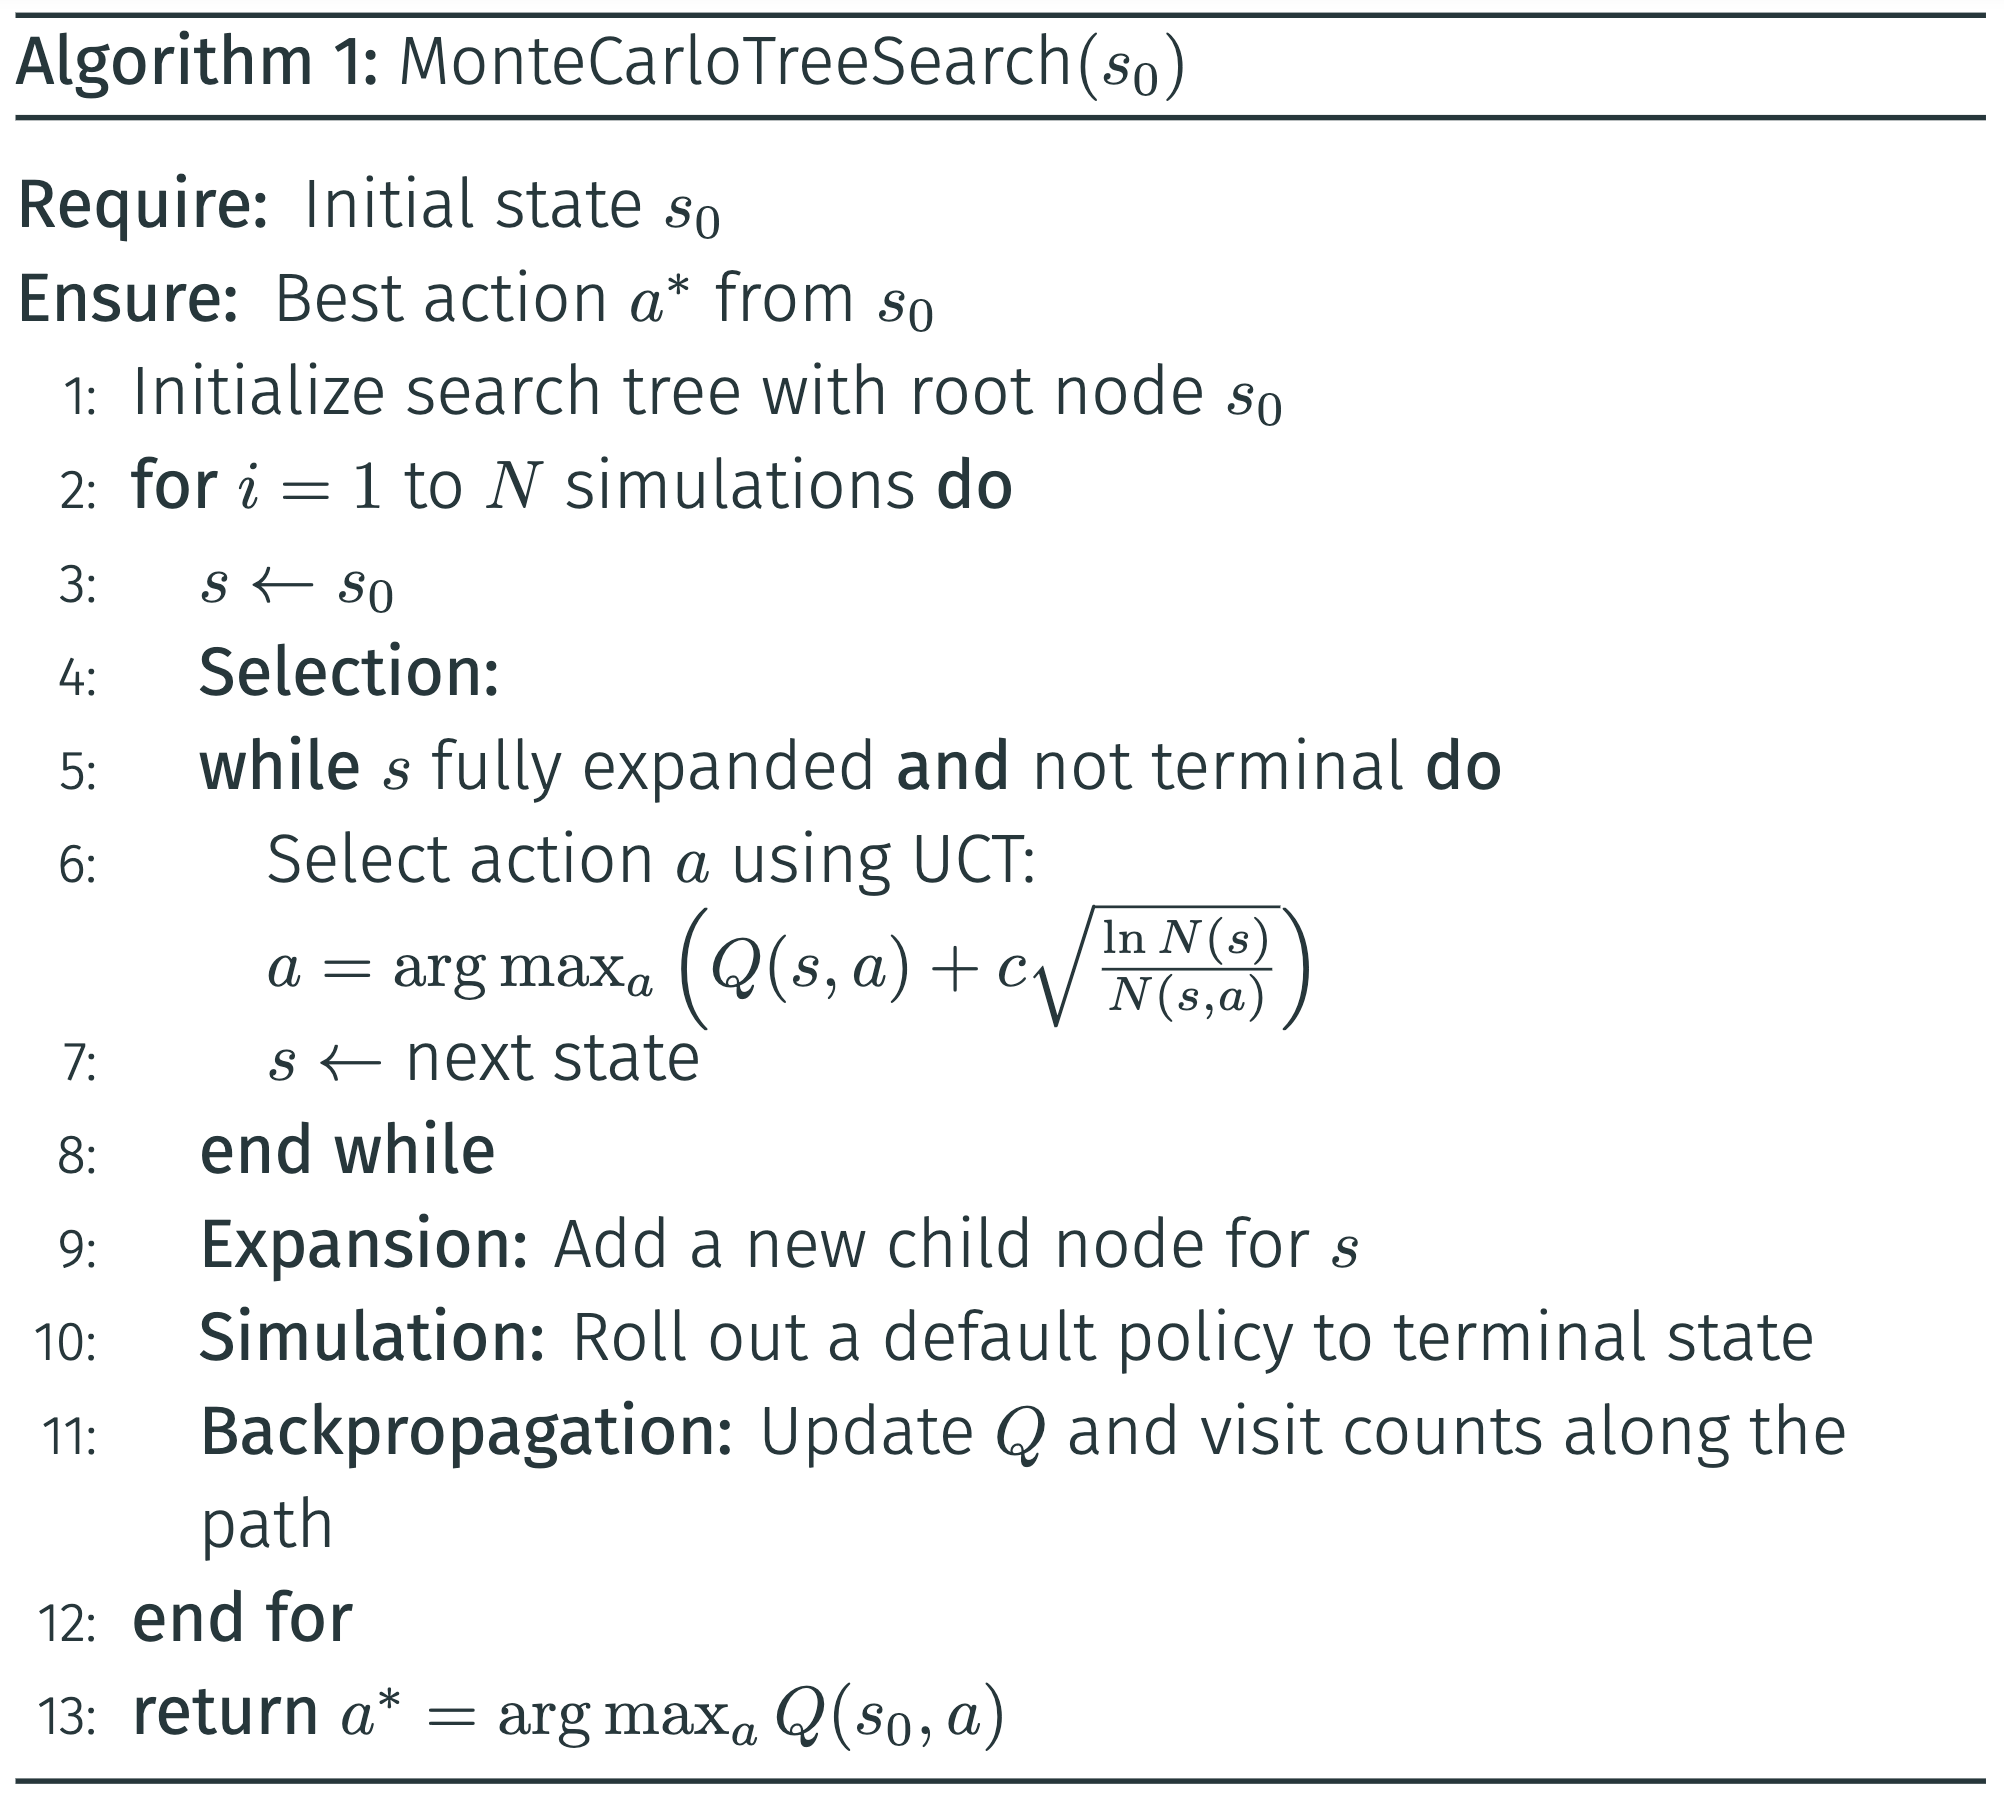

While this is the standard implementation of UCT, it is missing some important details that apply for our robotic task. For starters, our robot's action space is continuous. What does it mean that a node is "fully expanded" in this case? In addition, our robot's environment is stochastic, meaning that taking the same action in the same state can lead to different outcomes. But a node's children are typically defined as the possible per action, which now can lead to multiple states. We will address these issues in our implementation.

### Simulator API

The one thing that every vanilla UCT implementation needs is a simulator. The simulator is responsible for providing the MCTS algorithm with the ability to sample actions and states from the environment, as well as perform rollouts to estimate the value of states. Let's define the interface for our simulator

`Simulator` is provided in `task1.py`.

Let's implement a simulator for our block stacking task. This will also serve as the actual environment on which we will evaluate our MCTS agent.

Complete the implementation of the block stacking simulator:

**TODO:** implement `BlockStackingEnv` in `task1.py`. `OFFSET_RANGE`, `BlockStackingState`, and `BlockStackingAction` are provided there.

In [ ]:
# sanity check: BlockStackingEnv
check_env = t1.BlockStackingEnv(*get_check_model_data())
state = check_env.reset()

# actions are random offsets within OFFSET_RANGE, on both axes
actions = [check_env.sample_action(state) for _ in range(1000)]
offsets = np.array([[action.offset_x, action.offset_y] for action in actions], dtype=float)
test.assertTrue(np.all((offsets >= t1.OFFSET_RANGE[0]) & (offsets <= t1.OFFSET_RANGE[1])))
test.assertGreater(offsets.std(axis=0).min(), 0.004)

# at the start, the blocks are apart from each other
test.assertFalse(check_env.done())
test.assertFalse(check_env.success(), "the blocks are apart, but this is a success")

# a tower with all blocks at zero offset is a success
check_env.set_state(t1.BlockStackingState(stacked_blocks_offsets=[np.zeros(2)] * 4))
t1.wait(check_env.model, check_env.data, 1.0)  # let the simulation settle
test.assertTrue(check_env.done())
test.assertTrue(check_env.success(), "a tower with all blocks at zero offset is not a success")

# a tower is not a success if any of its blocks falls off
for falling_block in [1, 3]:
    tower_offsets = [np.zeros(2)] * 4
    tower_offsets[falling_block] = np.array([0.1, 0.0])
    check_env.set_state(t1.BlockStackingState(stacked_blocks_offsets=tower_offsets))
    t1.wait(check_env.model, check_env.data, 1.0)
    test.assertFalse(check_env.success(), f"block {falling_block} fell off the tower, but this is a success")

print(f"BlockStackingEnv sanity checks passed. random action offset = {np.round(offsets[0], 4).tolist()}")

Let's take a step in our simulation and check that everything is working as expected

In [ ]:
env = t1.BlockStackingEnv(model, data)
env.reset()
media.show_image(env.render())
action = env.sample_action(env.state)
next_state, total_return, done, info = env.step(action)
print(f"Reward: {total_return}, Done: {done}")
media.show_image(env.render())


### Tree Components

We now define the components of the UCT tree. In the standard UCT implementation, we There are only nodes which point to their child nodes. However, in our case, we need to account for the stochasticity of the environment and the continuous action space. Therefore, besides the `MCTSNode` component, we will also define an `MCTSEdge` component representing the action taken to transition from one node to another. A node has multiple edges, and each edge can lead to multiple child nodes representing the different possible outcomes of taking that action.

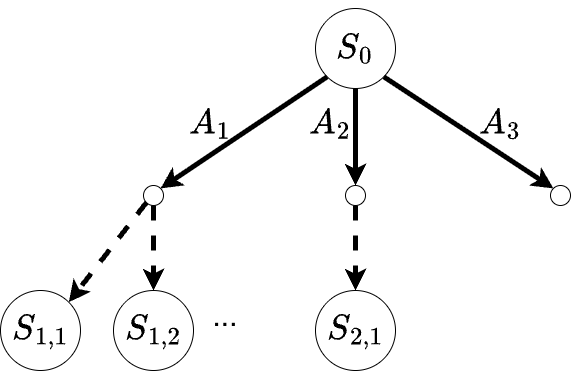

Each edge object will be responsible for calculating its own UCB value. A reminder of the UCB formula is as follows:
$$
UCB(s, a) = Q(s, a) + C \sqrt{\frac{\ln N_{s}}{n_{s,a}}}
$$
where Q(s, a) is the average reward of taking action a from state s, $N_s$ is the total number of times state s has been visited, $n_{s,a}$ is the number of times action a has been taken from state s, and C is a constant that balances exploration and exploitation. The $Q$-value is calculated as follows:
$$
Q(s, a) = \frac{W(s, a)}{n_{s,a}}
$$
where W(s, a) is the total return accumulated from taking action a from state s.

Using this method, each node object can calculate the top UCB edge to select an action during the selection phase of UCT.

Implement the UCB methods below:

**TODO:** implement `MCTSNode` and `MCTSEdge` in `task1.py`.

In [ ]:
# sanity check: MCTSNode and MCTSEdge
# a root visited 10 times, with two edges. edge_a has the better Q value, but edge_b was
# visited less
root = t1.MCTSNode(state=None, visits=10)
edge_a = t1.MCTSEdge(parent=root, action="a", outcomes=[], visits=8, total_return=6.0)
edge_b = t1.MCTSEdge(parent=root, action="b", outcomes=[], visits=2, total_return=1.0)
root.outgoing_edges = [edge_a, edge_b]

test.assertAlmostEqual(edge_a.q(), 0.75)
test.assertAlmostEqual(edge_b.q(), 0.5)
test.assertAlmostEqual(edge_a.ucb(2 ** 0.5), 0.75 + 2 ** 0.5 * np.sqrt(np.log(10) / 8))
test.assertAlmostEqual(edge_b.ucb(2 ** 0.5), 0.5 + 2 ** 0.5 * np.sqrt(np.log(10) / 2))
test.assertAlmostEqual(edge_a.ucb(0.0), 0.75)

# without exploration, the edge with the better Q value is selected. with exploration, the
# less visited edge is selected
best_edge = root.top_ucb_edge(0.0)
test.assertTrue(best_edge is edge_a, f"without exploration, edge a should be selected, got {getattr(best_edge, 'action', None)}")
best_edge = root.top_ucb_edge(2 ** 0.5)
test.assertTrue(best_edge is edge_b, f"with exploration, edge b should be selected, got {getattr(best_edge, 'action', None)}")

# an edge that was never visited is selected first
edge_c = t1.MCTSEdge(parent=root, action="c", outcomes=[])
root.outgoing_edges.append(edge_c)
best_edge = root.top_ucb_edge(2 ** 0.5)
test.assertTrue(best_edge is edge_c, f"the unvisited edge c should be selected, got {getattr(best_edge, 'action', None)}")

print(
    "MCTSNode and MCTSEdge sanity checks passed. "
    f"UCB values = {edge_a.ucb(2 ** 0.5):.3f}, {edge_b.ucb(2 ** 0.5):.3f}, {edge_c.ucb(2 ** 0.5)}"
)

### MCTS Stages

![MCTS stages](https://www.researchgate.net/profile/Jacek-Mandziuk/publication/320003615/figure/fig1/AS:553453972066304@1508965117895/Four-phases-of-the-MCTS-algorithm-The-figure-replicates-an-illustration-presented-in-3.png)

Recall the stages of MCTS:
1. **Selection**: Starting from the root node, select child nodes child nodes (in UCT this is based on UCB values) until a node that requires expanding is found, or a terminal node is reached.
2. **Expansion**: If the selected node is not terminal, create one or more child nodes and select one of them.
3. **Simulation**: From the selected node, run a simulation (also called a playout or rollout) to a terminal state by selecting actions according to a default policy (often random).
4. **Backpropagation**: Use the result of the simulation to update information in the nodes and edges along the path from the selected node back to the root.

#### Progressive Widening

In the selection stage, the MCTS algorithm calls for traversing the tree until a node that is not fully expanded or a terminal node is reached. What does "fully expanded" mean when actions are continuous? We cannot hope to enumerate an infinite number of actions.

The solution is to define a threshold for the number of children a node should have before we consider it fully expanded, and slowly grow this threshold as the number of visits to the node increases. This is called "progressive widening". We calculate the limit on the number of children as follows:
$$
PW(s) = \max(1, k \cdot N_{s}^{\alpha})
$$
The goal is to ensure that as you gain more computational budget (more visits $N_s$), you gradually consider more unique actions, but slowly enough that you still have time to search deep into the subtrees of the existing actions. The hyperparameters play an important role in balancing this trade-off:
- $k\in\mathbb{R}$ (the scale): Controls the overall number of children allowed. A larger k means more children can be added sooner.
- $\alpha \in (0,1)$ (the throttle): Controls the rate of growth of the number of children. A smaller $\alpha$ means the number of children grows more slowly with the number of visits.

Implement the progressive widening limit method below:

**TODO:** implement `progressive_widening_limit` in `task1.py`.

In [ ]:
# sanity check: progressive_widening_limit
# a node may always have at least one child, even before its first visit
test.assertEqual(t1.progressive_widening_limit(0, k=1.0, alpha=0.5), 1)
test.assertEqual(t1.progressive_widening_limit(1, k=1.0, alpha=0.5), 1)

# the limit grows with the number of visits
test.assertEqual(t1.progressive_widening_limit(4, k=1.0, alpha=0.5), 2)
test.assertEqual(t1.progressive_widening_limit(100, k=1.0, alpha=0.5), 10)

# k scales the limit, and a smaller alpha slows down its growth
test.assertEqual(t1.progressive_widening_limit(100, k=2.0, alpha=0.5), 20)
test.assertEqual(t1.progressive_widening_limit(16, k=1.0, alpha=0.25), 2)

limits = [t1.progressive_widening_limit(n, k=1.0, alpha=0.5) for n in [0, 1, 4, 9, 16, 25]]
print(f"progressive_widening_limit sanity checks passed. limits for 0, 1, 4, 9, 16, 25 visits = {limits}")

#### Selection

We are now ready to implement the selection stage. Note that we need to select a node that represents a state, not an edge that represents an action. Therefore, to select a node, we might need to expand a new outcome at a chosen edge. Notice that, again, there are an infinite number of possible outcomes for a given action in a continuous action space. Therefore, we will use the same progressive widening trick to determine whether to expand a new outcome or select an existing one. This is called Double Progressive Widening (DPW).

If the number of visits to the edge is below the progressive widening limit, we expand a new outcome by performing the action represented by that edge. Otherwise, we select an existing outcome by sampling from the existing child nodes, distributed according to their visit counts. Specifically:
$$
outcome \sim \left(\frac{n_{s,a}^{outcome}}{\sum_{o} n_{s,a}^{o}} \text{ for } s \in edge\right)
$$

Implement DPW node selection:

**TODO:** implement `expand_outcome`, `dpw_select_outcome`, and `dpw_select_node` in `task1.py`.

The sanity checks for the MCTS stages run on `CheckSimulator`, a fast stand-in for `BlockStackingEnv` without physics. Each step stacks the next block at exactly the chosen offset, and the episode ends when all four blocks are stacked.

In [ ]:
class CheckSimulator(t1.Simulator):
    """
    A fast stand-in for `BlockStackingEnv` without physics, used by the sanity checks.
    Each step stacks the next block at exactly the chosen offset. The episode ends when
    all four blocks are stacked, with a reward of 1 if all offsets are within 5 mm of the
    base block, and 0 otherwise.
    """

    def __init__(self):
        self.state = None

    def reset(self):
        self.state = t1.BlockStackingState(stacked_blocks_offsets=[np.zeros(2)])
        return deepcopy(self.state)

    def step(self, action):
        self.state = deepcopy(self.state)
        self.state.stacked_blocks_offsets.append(np.array([action.offset_x, action.offset_y]))
        done = self.done()
        success = done and all(np.abs(offset).max() <= 0.005 for offset in self.state.stacked_blocks_offsets)
        return deepcopy(self.state), float(success), done, {}

    def set_state(self, state):
        self.state = deepcopy(state)

    def sample_action(self, state):
        offset_x, offset_y = np.random.uniform(*t1.OFFSET_RANGE, size=2)
        return t1.BlockStackingAction(offset_x=offset_x, offset_y=offset_y)

    def done(self):
        return len(self.state.stacked_blocks_offsets) >= 4

In [ ]:
# sanity check: expand_outcome, dpw_select_outcome, and dpw_select_node
check_sim = CheckSimulator()
root = t1.MCTSNode(state=check_sim.reset())
edge = t1.MCTSEdge(parent=root, action=t1.BlockStackingAction(offset_x=0.002, offset_y=-0.003), outcomes=[])
root.outgoing_edges.append(edge)

# expanding an outcome simulates the edge's action from the edge's parent state
outcome = t1.expand_outcome(edge, check_sim)
test.assertTrue(len(edge.outcomes) == 1 and edge.outcomes[0] is outcome, "the new outcome is not in edge.outcomes")
test.assertTrue(outcome.incoming_edge is edge, "the incoming edge of the new outcome is wrong")
test.assertEqual(len(outcome.state.stacked_blocks_offsets), 2)
np.testing.assert_allclose(outcome.state.stacked_blocks_offsets[-1], [0.002, -0.003])
test.assertEqual(len(root.state.stacked_blocks_offsets), 1, "the parent state changed")

# with one visit, the edge has enough outcomes (the PW limit is 1), so the existing
# outcome is selected
edge.visits, outcome.visits = 1, 1
for _ in range(10):
    selected = t1.dpw_select_outcome(edge, check_sim, pw_k=1.0, pw_alpha=0.5)
    test.assertTrue(selected is outcome, "with one visit, the existing outcome should be selected")
test.assertEqual(len(edge.outcomes), 1)

# with four visits, the PW limit is 2, so a new outcome is expanded
edge.visits, outcome.visits = 4, 4
new_outcome = t1.dpw_select_outcome(edge, check_sim, pw_k=1.0, pw_alpha=0.5)
test.assertEqual(len(edge.outcomes), 2, "with four visits, a new outcome should be expanded")
test.assertTrue(edge.outcomes[1] is new_outcome, "the new outcome should be selected")

# existing outcomes are sampled according to their visits. the new outcome has no visits yet
for _ in range(20):
    selected = t1.dpw_select_outcome(edge, check_sim, pw_k=1.0, pw_alpha=0.5)
    test.assertTrue(selected is outcome, "an outcome with no visits was selected")

# a root that was never visited can have a new edge, so selection stops at the root
new_root = t1.MCTSNode(state=check_sim.reset())
selected = t1.dpw_select_node(new_root, check_sim, exploration_constant=2 ** 0.5, pw_k=1.0, pw_alpha=0.5)
test.assertTrue(selected is new_root, "selection should stop at a root that was never visited")

# a root with one visit and one edge is expanded enough, so selection continues to the
# edge's only outcome. that outcome has no edges yet, so selection stops there
root = t1.MCTSNode(state=check_sim.reset(), visits=1)
edge = t1.MCTSEdge(parent=root, action=t1.BlockStackingAction(offset_x=0.0, offset_y=0.0), outcomes=[], visits=1)
root.outgoing_edges.append(edge)
check_sim.set_state(root.state)
child = t1.MCTSNode(state=check_sim.step(edge.action)[0], incoming_edge=edge, visits=1)
edge.outcomes.append(child)
selected = t1.dpw_select_node(root, check_sim, exploration_constant=2 ** 0.5, pw_k=1.0, pw_alpha=0.5)
test.assertTrue(selected is child, "selection should continue from the root to its only outcome")

print(
    "expand_outcome, dpw_select_outcome, and dpw_select_node sanity checks passed. "
    f"expanded outcome offsets = {np.round(outcome.state.stacked_blocks_offsets, 3).tolist()}"
)

#### Exapnsion

We already saw how to expand a new outcome in the selection stage. The expansion stage is similar, except that we are expanding a new action edges instead of a new outcome. Since we have no prior knowledge about which actions are better, we sample a random action from the action space.

Implement node expansion:

**TODO:** implement `dpw_expand_node` in `task1.py`.

In [ ]:
# sanity check: dpw_expand_node
check_sim = CheckSimulator()
root = t1.MCTSNode(state=check_sim.reset())

# expanding adds a new edge with a random action, and one outcome of that action
outcome = t1.dpw_expand_node(root, check_sim)
test.assertEqual(len(root.outgoing_edges), 1)
edge = root.outgoing_edges[0]
test.assertTrue(edge.parent is root, "the parent of the new edge is wrong")
test.assertTrue(len(edge.outcomes) == 1 and edge.outcomes[0] is outcome, "the new outcome is not in edge.outcomes")
test.assertTrue(outcome.incoming_edge is edge, "the incoming edge of the new outcome is wrong")
np.testing.assert_allclose(outcome.state.stacked_blocks_offsets[-1], [edge.action.offset_x, edge.action.offset_y])

# a second expansion adds another edge, with a different action
second_outcome = t1.dpw_expand_node(root, check_sim)
test.assertEqual(len(root.outgoing_edges), 2)
second_edge = root.outgoing_edges[1]
test.assertTrue(second_outcome.incoming_edge is second_edge, "the incoming edge of the new outcome is wrong")
test.assertFalse(
    np.allclose([edge.action.offset_x, edge.action.offset_y], [second_edge.action.offset_x, second_edge.action.offset_y]),
    "both expansions have the same action, but actions should be random",
)

print(
    "dpw_expand_node sanity checks passed. "
    f"expanded action offset = {np.round([edge.action.offset_x, edge.action.offset_y], 4).tolist()}"
)

#### Simulation (Rollout)

The simulation stage is straightforward. We simply perform random actions from the current state until we reach a terminal state, and return the accumulated reward. This is implemented for you.

`simulate_rollout` is provided in `task1.py`.

There are many ways to select the rollout policy for simulation. A simple approach is to select actions uniformly at random from the action space. However, due to the fragile nature of the block towers, random actions often lead to tower collapse quickly, and thus our UCT will need much planning time to find example of good paths to take. This is especially true with stochastic outcomes, where each action can have multiple possible results. A more sophisticated approach is to use a heuristic-based policy to guide the simulation.

From what we have seen so far, a policy that can sometimes lead to successful results is the zero offset policy. We will use this policy for our rollout simulations.

`zero_offset_rollout_policy` is provided in `task1.py`.

#### Backpropagation

In the backpropagation stage, we need to update the visit counts and total returns for each edge along the path from the selected node back to the root. For each edge, we increment the visit count and add the accumulated reward from the simulation to the total return.

Implement backpropagation:

**TODO:** implement `backpropagate` in `task1.py`.

In [ ]:
# sanity check: backpropagate
# a root with one edge that leads to one outcome
root = t1.MCTSNode(state=None)
edge = t1.MCTSEdge(parent=root, action=None, outcomes=[])
child = t1.MCTSNode(state=None, incoming_edge=edge)
root.outgoing_edges.append(edge)
edge.outcomes.append(child)

# two simulations from the outcome, one successful and one not, update every node and
# edge on the way back to the root
t1.backpropagate(child, 1.0)
t1.backpropagate(child, 0.0)
for name, element in [("outcome", child), ("edge", edge), ("root", root)]:
    test.assertEqual(element.visits, 2, f"{name} visits")
    test.assertAlmostEqual(element.total_return, 1.0, msg=f"{name} total return")

print(f"backpropagate sanity checks passed. root visits = {root.visits}, root total return = {root.total_return}")

### UCT Implementation

We now have the necessary components to implement the UCT algorithm with Double Progressive Widening, as described above. We implement this for you below.

`ContinuousActionStochasticOutcomeUCT` is provided in `task1.py`.

## Evaluation

Let's see our UCT implementation in action. Below we implement a single run of the environment. The loop is as follows:
1. Start from the root node representing the initial state.
2. Run UCT up to a specified amount of time
3. Select the best action from the root node based on visit counts
4. Step the environment with the selected action
5. Set the new state to be the root node and repeat until the environment is done

`run_mcts_planning` is provided in `task1.py`.

Choose the planning time and run the evaluation step. How much time does the agent need to plan effectively?

**TODO:** set `PLANNING_TIME` in `task1.py`.

In [ ]:
# set PLANNING_TIME in task1.py

env.reset()
media.show_image(env.render())

sim_env = env.clone()

uct = t1.ContinuousActionStochasticOutcomeUCT(
    sim=sim_env,
    rollout_policy=t1.zero_offset_rollout_policy,
    pw_k=1.0,
    pw_alpha=0.5,
)

root_node = t1.MCTSNode(state=sim_env.state)
nodes, frames = t1.run_mcts_planning(
    env,
    mcts=uct,
    root_node=root_node,
    planning_time=t1.PLANNING_TIME,
    exploration_constant=2 ** 0.5,  # regret-minimizing choice for exploration constant in UCT
    framerate=0
)

**Next:** continue to Task 2 in `task2.ipynb`.